## CS2 Integrity Watch: demo map from the LinuxONE API

In [1]:
import pandas as pd, requests
API = "http://148.100.79.57:38888"
requests.get(f"{API}/api/health").json()

{'ok': True,
 'arch': 's390x',
 'uname': 'Linux s390x',
 'python': '3.12.15',
 'hostname': 'tylerinstance1',
 'models_loaded': ['logit-v1', 'xgb-v1'],
 'model_error': None,
 'n_maps': 1014,
 'uptime_s': 5063.8,
 'resolution_floor_s': 60}

In [2]:
d = requests.get(f"{API}/api/series/2393088-2").json()
df = pd.DataFrame(d["rounds"])
cols = ["round_num", "score_team1", "score_team2", "buy_team1", "buy_team2",
        "equip_diff_team1_minus_team2", "model_p", "market_p", "gap", "injected"]
df.loc[10:16, cols]

,round_num,score_team1,score_team2,buy_team1,buy_team2,equip_diff_team1_minus_team2,model_p,market_p,gap,injected
10,11,7,3,full,semi,19700.0,0.8506,0.5600,-0.2906,False
11,12,7,4,full,full,2150.0,0.7595,0.6850,-0.0745,False
12,13,7,5,force,eco,2250.0,0.7065,0.5050,-0.2015,False
13,14,8,5,semi,semi,4400.0,0.7458,0.1740,-0.5719,True
14,15,9,5,full,semi,7350.0,0.8242,0.4451,-0.3791,True
15,16,9,6,semi,full,-6100.0,0.7334,0.4152,-0.3183,True
16,17,10,6,full,full,-4300.0,0.8215,0.5250,-0.2965,False


In [3]:
pd.DataFrame(requests.get(f"{API}/api/summary").json()["model_metrics"]).T[["brier", "logloss", "n"]]

,brier,logloss,n
logit,0.1775,0.5266,9163.0
xgb,0.1768,0.5249,9163.0
baseline_coinflip,0.2500,NaN,NaN


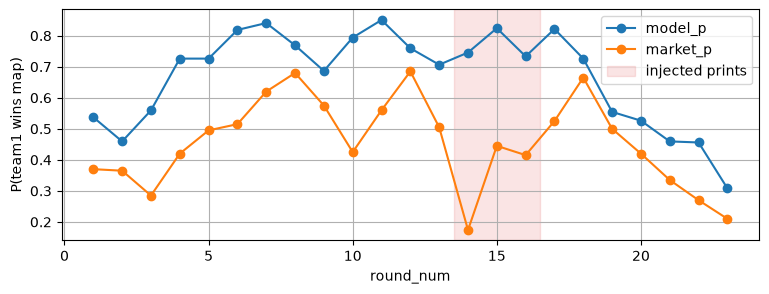

In [4]:
ax = df.plot(x="round_num", y=["model_p", "market_p"], marker="o", figsize=(9, 3),
             color=["#1f77b4", "#ff7f0e"], grid=True)
ax.axvspan(13.5, 16.5, color="#d62728", alpha=.12, label="injected prints")
ax.set_ylabel("P(team1 wins map)"); ax.legend();